<a href="https://colab.research.google.com/github/nuruyar/ai_master_computervision/blob/main/lab_6_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from PIL import Image
from pylab import *
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.ndimage as snd
from scipy.ndimage import *
from skimage.feature import (match_descriptors, corner_harris, corner_peaks, ORB, plot_matched_features)
from skimage.color import rgb2gray
from skimage import data
from skimage import transform as tf

import cv2
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


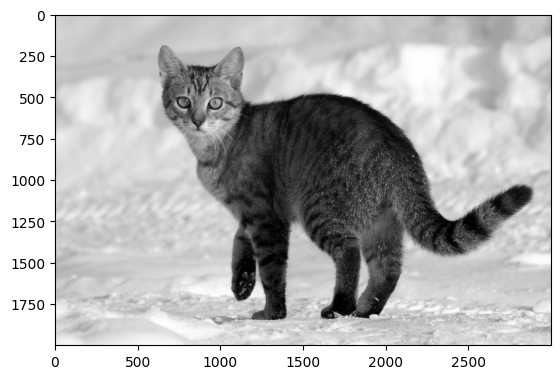

uint8
float64


In [ ]:
path = "/content/drive/MyDrive/Colab Notebooks/Bilgisayarla Görme"
im_color = np.array(Image.open(path + "/kedi.jpeg"))
im_gray = np.array(Image.open(path + "/kedi.jpeg").convert('L'), np.float64)
imgplot = plt.imshow(im_gray, cmap='gray')
plt.show()
print(str(im_color.dtype))
print(str(im_gray.dtype))
img1_cat = cv2.imread(path + "/kedi.jpeg")
img2_cat = cv2.imread(path + "/kedi.jpeg")

**TEMPLATE MATCHING **

(500, 500, 3)


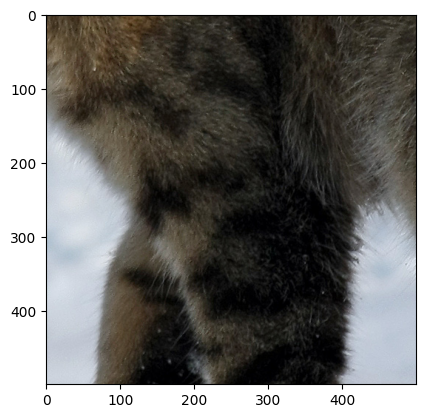

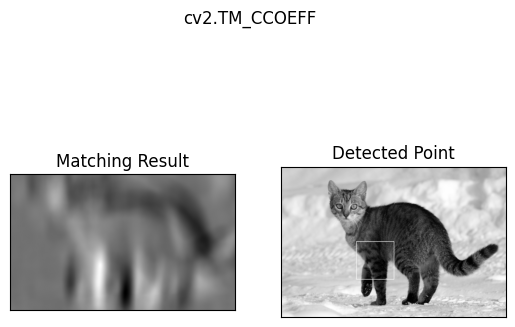

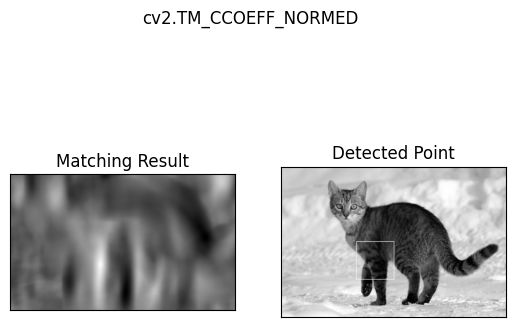

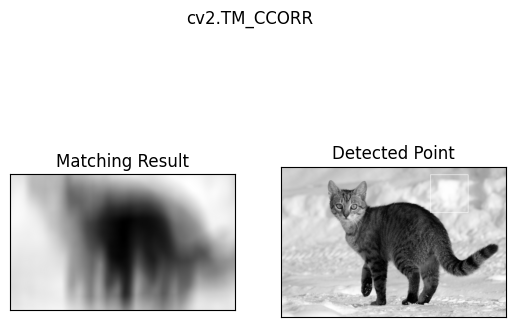

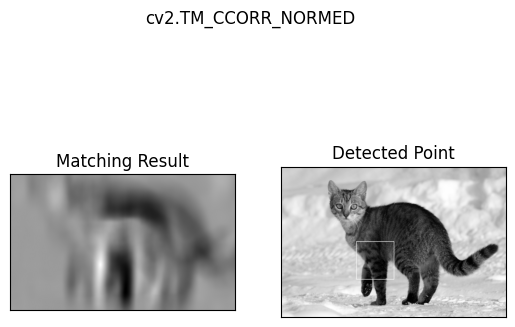

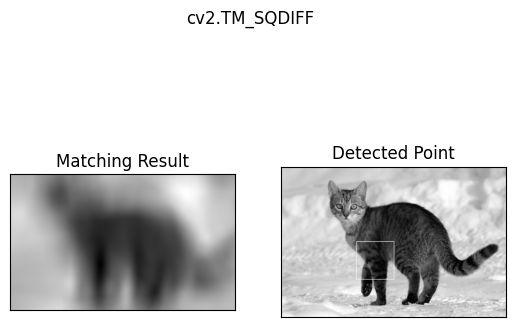

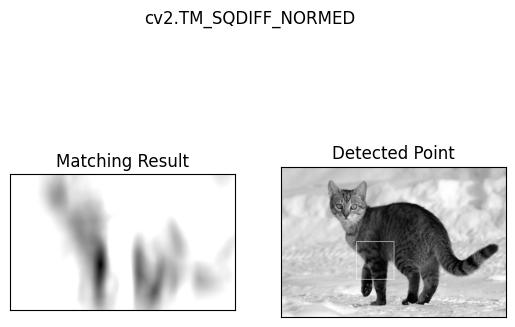

In [ ]:
im_trim = np.array(im_color[1000:1500, 1000:1500,:])
print(im_trim.shape)
plt.imshow(im_trim)
plt.show()
pil_img = Image.fromarray(im_trim)
pil_img.save(path + "/kedi_trimed.jpeg")

img_ori = cv2.imread(path + "/kedi.jpeg",0)
template = cv2.imread(path + "/kedi_trimed.jpeg",0)
w, h = template.shape[::-1]

methods = ['cv2.TM_CCOEFF', 'cv2.TM_CCOEFF_NORMED', 'cv2.TM_CCORR','cv2.TM_CCORR_NORMED', 'cv2.TM_SQDIFF', 'cv2.TM_SQDIFF_NORMED']

for meth in methods:
  img = img_ori.copy()
  method = eval(meth)

  res = cv2.matchTemplate(img,template,method)
  min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

  #if the method is TM_SQDIFF or TM_SQDIFF_NORMED take minimum

  if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
    top_left = min_loc
  else:
    top_left = max_loc

  bottom_right = (top_left[0] + w, top_left[1] + h)

  cv2.rectangle(img,top_left, bottom_right, 255, 5)

  plt.subplot(121),plt.imshow(res,cmap = 'gray')
  plt.title('Matching Result'), plt.xticks([]), plt.yticks([])
  plt.subplot(122),plt.imshow(img,cmap = 'gray')
  plt.title('Detected Point'),plt.xticks([]),plt.yticks([])
  plt.suptitle(meth)
  plt.show()

**NORMALIZER**

In [ ]:
def maxmin_norm(I):
  min_image = min(I.flatten())
  Inorm = I-min_image
  max_image = max(Inorm.flatten())
  Inorm = Inorm/max_image
  Inorm = Inorm*255
  return Inorm

**FAST DETECTOR**

In [ ]:
def compute_fast_det(img, is_nms=True, tresh = 10):
  fast =cv2.FastFeatureDetector_create()
  if not is_nms:
    fast.setNonmaxSuppression(0)
  fast.setThreshold(tresh)
  kp = fast.detect(img,None)
  cv2.drawKeypoints(img, kp, img, color=(0,0,255))
  return img

In [ ]:
def plot_imgs(img1, img2, th):
  fig, ax = plt.subplots(nrows=1, ncols=2)
  fig.set_figwidth(15)
  fig.set_figheight(5)
  ax[0].imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
  ax[0].set_title('Fast Points on Image(th='+ str(th)+ ')')
  ax[0].axis('off')
  ax[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
  ax[1].set_title('Fast Points on Image(th ='+ str(th)+ ')')
  ax[1].axis('off')
  #plt.savefig(path+"images/png/fast_deatures.png")
  plt.show()

**FAST DETECTOR TEST**

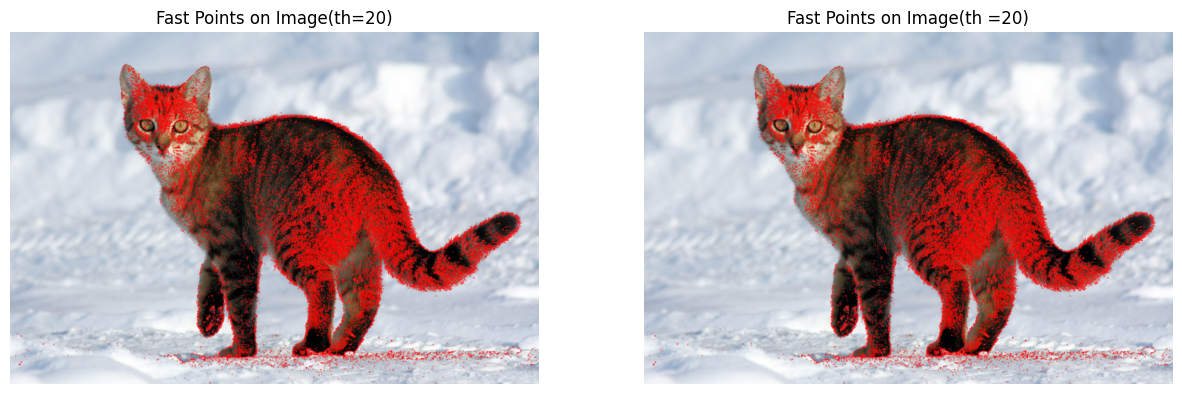

In [ ]:

# tform = tf.AffineTransform(scale=(1.3,1.1), rotation=0.5, translation=(0, -200))
# imgray2 = tf.warp(im_gray, tform)
# pil_img.save(path+"/kedi.jpeg")
# img2 = cv2.imread(path+"/kedi.jpeg")

treshold = 20

img1 = img1_cat.copy()
img2 = img2_cat.copy()
img1 = compute_fast_det(img1, True, tresh = treshold)
img2 = compute_fast_det(img2, True, tresh = treshold)


#Do plot
plot_imgs(img1, img2, treshold)



**DOG SCALE SPACE**

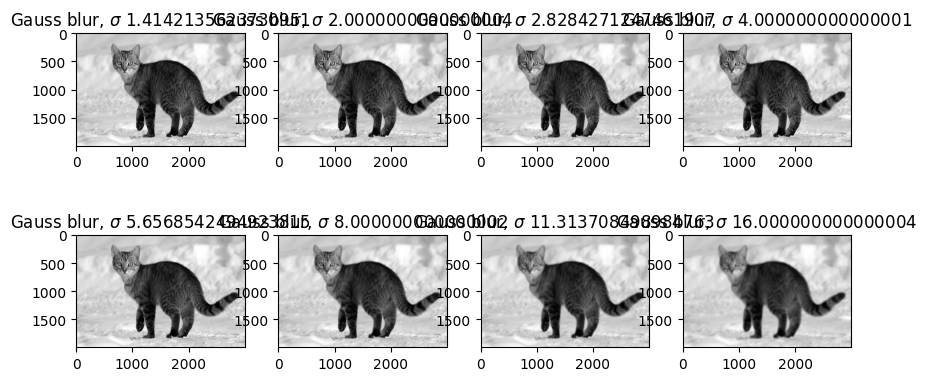

In [ ]:
fig, ax = plt.subplots(nrows=2, ncols=4)
plt.gray()
fig.set_figwidth(20)
fig.set_figwidth(10)
sigma = 1
out = np.zeros((im_gray.shape[0],im_gray.shape[1],8))
for i in range(0,8):
  out[:,:,i] = gaussian_filter(im_gray, sigma)
  sigma = np.sqrt(2)*sigma
  plt.subplot(2,4,i+1), plt.imshow(out[:,:,i])
  plt.title((r'Gauss blur, $\sigma$ ' +str(sigma)))
plt.show()

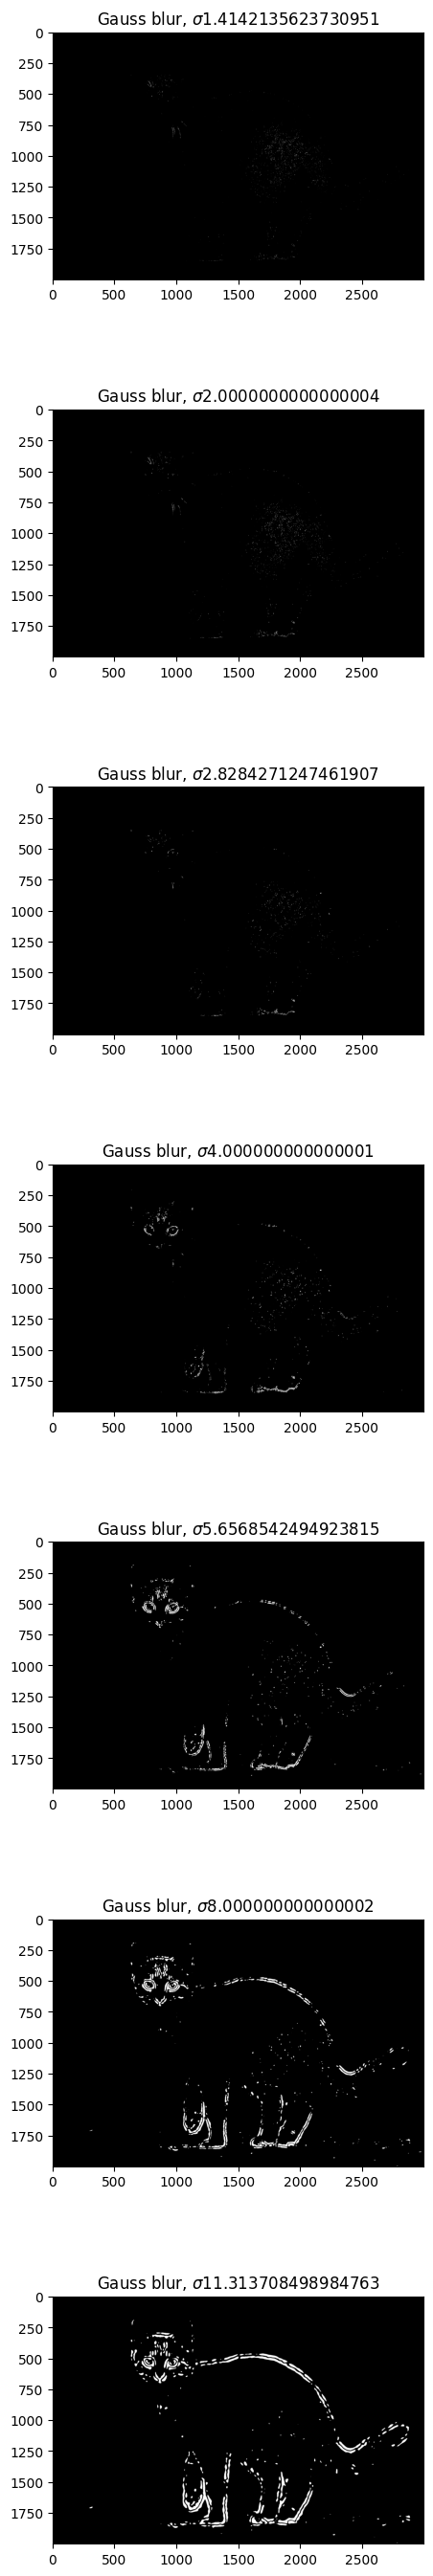

In [ ]:
fig, ax = plt.subplots(nrows=7, ncols=1)
fig.set_figwidth(5)
fig.set_figheight(35)
plt.gray()
sigma = 1
for i in range(0,7):
  dif = out[:,:,i+1]-out[:,:,i]
  tresh = 0.3*np.abs(dif.flatten()).max()
  sigma = np.sqrt(2)*sigma
  plt.subplot(7,1,i+1), plt.imshow(maxmin_norm(np.float32(np.abs(dif)>tresh)))
  plt.title((r'Gauss blur, $\sigma$' +str(sigma)))
plt.show()

**SIFT DETECTOR**

In [ ]:
def compute_sift_features(img):
  gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
  sift = cv2.SIFT_create()
  kp = sift.detect(gray,None)
  cv2.drawKeypoints(img,kp,img)
  return img

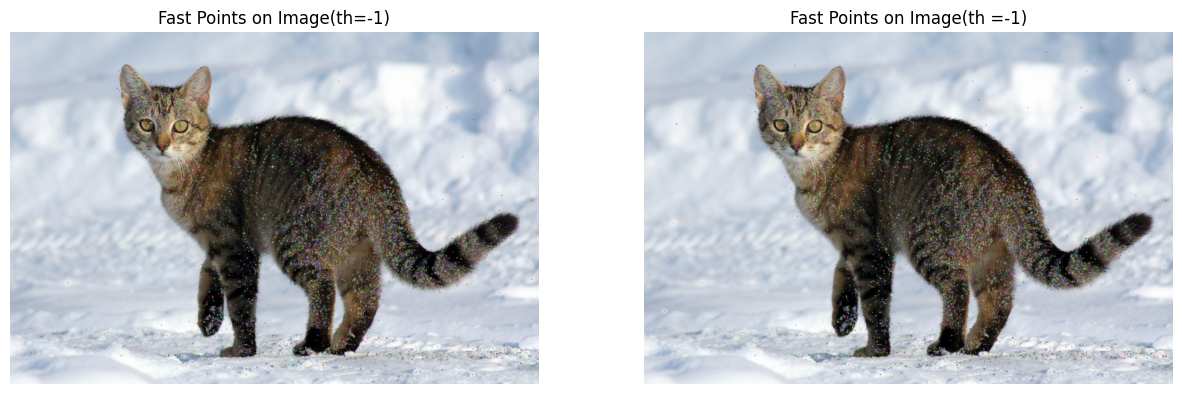

In [ ]:
img1 = img1_cat.copy()
img2 = img2_cat.copy()
img1 = compute_sift_features(img1)
img2 = compute_sift_features(img2)
plot_imgs(img1, img2, -1)

(200, 2) (200, 256) bool
(200, 2)
(198, 2)


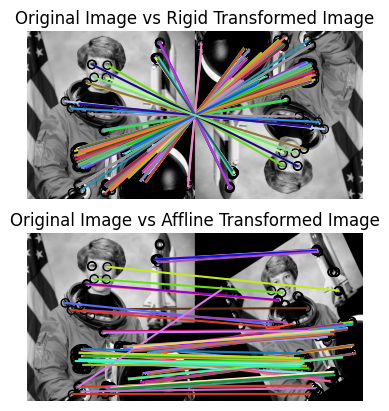

In [ ]:
img1 = rgb2gray(data.astronaut())
img2 = tf.rotate(img1, 180)
tform = tf.AffineTransform(scale=(1.3,1.1),rotation=0.5, translation=(0, -200))
img3 = tf.warp(img1, tform)
descriptor_extractor = ORB(n_keypoints=200)

descriptor_extractor.detect_and_extract(img1)
keypoints1 = descriptor_extractor.keypoints
descriptors1 = descriptor_extractor.descriptors
print(''+str(keypoints1.shape)+' ' +str(descriptors1.shape)+' '+str(descriptors1.dtype))

descriptor_extractor.detect_and_extract(img2)
keypoints2 = descriptor_extractor.keypoints
print(''+str(keypoints2.shape))
descriptors2 = descriptor_extractor.descriptors
descriptor_extractor.detect_and_extract(img3)
keypoint3 = descriptor_extractor.keypoints
descriptors3 = descriptor_extractor.descriptors
matches12 = match_descriptors(descriptors1, descriptors2, cross_check=True)
matches13 = match_descriptors(descriptors1, descriptors3, cross_check=True)
print(''+str(matches12.shape))
fig, ax = plt.subplots(nrows=2, ncols=1)
plt.gray()
plot_matched_features(img1, img2, keypoints0=keypoints1, keypoints1=keypoints2, matches=matches12, ax=ax[0], keypoints_color='k', matches_color=None, only_matches=False, alignment='horizontal')
ax[0].axis('off')
ax[0].set_title("Original Image vs Rigid Transformed Image")
plot_matched_features(img1, img3, keypoints0=keypoints1, keypoints1=keypoint3, matches=matches13, ax=ax[1], keypoints_color='k', matches_color=None, only_matches=False, alignment='horizontal')
ax[1].axis('off')
ax[1].set_title("Original Image vs Affline Transformed Image")
plt.show()